# Ecommerce order risk classification ML Project

**📝 Problem Statement**

**Step 1: Import Libraries**

In [35]:
# data handling
import joblib
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# feature selection
from sklearn.feature_selection import VarianceThreshold

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier

# metrics
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

**Step 2: Load Dataset**

In [3]:
df = pd.read_csv("synthetic_ecommerce_order_risk_dataset.csv")

**Step 3: Understand Your Data (EDA)**

In [4]:
df.head()

,order_id,order_date,country,device_type,traffic_source,payment_method,product_category,customer_age_days,previous_orders,avg_order_value_eur,...,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud,risk_label
0,ORD-2024-001936,2024-01-03,Belgium,Mobile,Paid Ads,Credit Card,Sports,381,3,28.66,...,105.7,5,0,0,0,0,4.4,0,0,Normal
1,ORD-2025-006495,2025-11-26,Netherlands,Desktop,Email,Debit Card,Garden,561,6,41.93,...,528.2,4,0,0,0,0,4.8,0,0,Normal
2,ORD-2023-001721,2023-11-07,Netherlands,Mobile,Organic Search,Debit Card,Garden,324,2,102.67,...,175.1,5,0,0,0,0,3.3,0,0,Normal
3,ORD-2024-009121,2024-05-28,Netherlands,Mobile,Organic Search,Klarna,Electronics,378,3,72.71,...,271.4,3,0,0,0,0,4.2,1,0,Return Risk
4,ORD-2025-000361,2025-01-31,Netherlands,Desktop,Direct,Bank Transfer,Home & Kitchen,447,5,52.26,...,285.3,3,0,1,0,0,5.0,0,0,Normal


In [5]:
df.sample(5)

,order_id,order_date,country,device_type,traffic_source,payment_method,product_category,customer_age_days,previous_orders,avg_order_value_eur,...,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud,risk_label
576,ORD-2025-011176,2025-11-19,Netherlands,Mobile,Organic Search,PayPal,Fashion,141,1,17.09,...,770.6,4,0,0,0,0,4.6,0,0,Normal
7661,ORD-2023-007426,2023-03-24,Netherlands,Mobile,Organic Search,Gift Card,Garden,319,3,52.30,...,214.9,6,0,0,0,0,3.9,1,0,Return Risk
5558,ORD-2025-002550,2025-07-02,Netherlands,Mobile,Paid Ads,Debit Card,Fashion,115,0,27.78,...,175.3,3,0,0,0,0,4.0,1,0,Return Risk
1922,ORD-2024-011732,2024-01-08,Turkey,Mobile,Social Media,Bank Transfer,Garden,193,1,27.80,...,274.0,4,0,0,0,0,4.5,0,0,Normal
11915,ORD-2023-010174,2023-06-08,Belgium,Mobile,Direct,Bank Transfer,Electronics,309,2,32.44,...,598.2,4,0,0,0,0,4.5,0,0,Normal


In [6]:
df.columns

Index(['order_id', 'order_date', 'country', 'device_type', 'traffic_source',
       'payment_method', 'product_category', 'customer_age_days',
       'previous_orders', 'avg_order_value_eur', 'order_value_eur', 'quantity',
       'discount_rate', 'shipping_distance_km', 'delivery_days_estimated',
       'late_delivery_risk', 'address_mismatch', 'high_risk_ip',
       'customer_support_contacts', 'review_score', 'is_returned', 'is_fraud',
       'risk_label'],
      dtype='str')

In [7]:
df.dtypes

order_id                         str
order_date                       str
country                          str
device_type                      str
traffic_source                   str
payment_method                   str
product_category                 str
customer_age_days              int64
previous_orders                int64
avg_order_value_eur          float64
order_value_eur              float64
quantity                       int64
discount_rate                float64
shipping_distance_km         float64
delivery_days_estimated        int64
late_delivery_risk             int64
address_mismatch               int64
high_risk_ip                   int64
customer_support_contacts      int64
review_score                 float64
is_returned                    int64
is_fraud                       int64
risk_label                       str
dtype: object

In [8]:
df.nunique()

order_id                     12000
order_date                    1096
country                          8
device_type                      3
traffic_source                   6
payment_method                   6
product_category                 8
customer_age_days             1131
previous_orders                 14
avg_order_value_eur           6467
order_value_eur               7517
quantity                         8
discount_rate                   73
shipping_distance_km          7086
delivery_days_estimated          9
late_delivery_risk               2
address_mismatch                 2
high_risk_ip                     2
customer_support_contacts        6
review_score                    36
is_returned                      2
is_fraud                         2
risk_label                       3
dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   12000 non-null  str    
 1   order_date                 12000 non-null  str    
 2   country                    12000 non-null  str    
 3   device_type                12000 non-null  str    
 4   traffic_source             12000 non-null  str    
 5   payment_method             12000 non-null  str    
 6   product_category           12000 non-null  str    
 7   customer_age_days          12000 non-null  int64  
 8   previous_orders            12000 non-null  int64  
 9   avg_order_value_eur        12000 non-null  float64
 10  order_value_eur            12000 non-null  float64
 11  quantity                   12000 non-null  int64  
 12  discount_rate              12000 non-null  float64
 13  shipping_distance_km       12000 non-null  float64
 14  d

In [10]:
df.describe()

,customer_age_days,previous_orders,avg_order_value_eur,order_value_eur,quantity,discount_rate,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,352.789083,1.943417,48.940278,61.053339,2.171833,0.146857,479.196567,4.058917,0.060000,0.048583,0.044167,0.200667,4.412433,0.092667,0.037250
std,237.556088,1.902590,28.716864,55.540429,1.625534,0.113934,330.305205,1.105312,0.237497,0.215004,0.205474,0.478803,0.545286,0.289977,0.189382
min,5.000000,0.000000,8.000000,5.000000,1.000000,0.000000,5.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.300000,0.000000,0.000000
25%,177.000000,1.000000,29.070000,26.617500,1.000000,0.060000,236.100000,3.000000,0.000000,0.000000,0.000000,0.000000,4.100000,0.000000,0.000000
50%,299.000000,1.000000,42.100000,45.335000,2.000000,0.120000,404.450000,4.000000,0.000000,0.000000,0.000000,0.000000,4.500000,0.000000,0.000000
75%,475.000000,3.000000,61.010000,75.952500,3.000000,0.210000,645.225000,5.000000,0.000000,0.000000,0.000000,0.000000,4.900000,0.000000,0.000000
max,1832.000000,13.000000,350.450000,810.750000,8.000000,0.750000,2589.700000,9.000000,1.000000,1.000000,1.000000,5.000000,5.000000,1.000000,1.000000


**Step 4: Data Cleaning**

In [11]:
# 1. check null values
df.isnull().sum()

order_id                     0
order_date                   0
country                      0
device_type                  0
traffic_source               0
payment_method               0
product_category             0
customer_age_days            0
previous_orders              0
avg_order_value_eur          0
order_value_eur              0
quantity                     0
discount_rate                0
shipping_distance_km         0
delivery_days_estimated      0
late_delivery_risk           0
address_mismatch             0
high_risk_ip                 0
customer_support_contacts    0
review_score                 0
is_returned                  0
is_fraud                     0
risk_label                   0
dtype: int64

In [12]:
# 2. remove duplicates
print("Duplicate values: ",df.duplicated().sum())
df = df.drop_duplicates()

Duplicate values:  0


In [13]:
# 3. fix feature names
# df = df.rename(columns={"old","new"}) no need

In [14]:
# 4. fix data types

df['order_date'] = pd.to_datetime(df['order_date'],errors="coerce")

In [15]:
# 5. remove unwanted cols
df.drop(columns=['order_id'], inplace=True)

<Axes: >

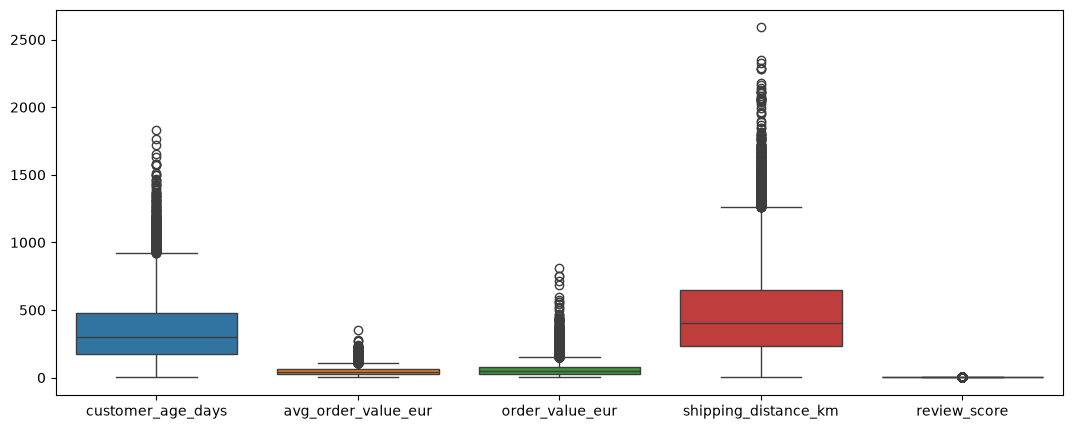

In [16]:
# 6. remove outliers
plt.figure(figsize=(13,5))
sns.boxplot(df[['customer_age_days','avg_order_value_eur', 'order_value_eur','shipping_distance_km','review_score']])

In [17]:
cols = ['customer_age_days','avg_order_value_eur', 'order_value_eur','shipping_distance_km','review_score']
for i,col in enumerate(cols,start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col]<lower) | (df[col]>upper)]
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col]<lower) | (df[col]>upper)]
    
    print(f"\n{i}. {col}")
    print(f"before_outliers: {len(before_outliers)}")
    print(f"after_outliers: {len(after_outliers)}")


1. customer_age_days
before_outliers: 364
after_outliers: 0

2. avg_order_value_eur
before_outliers: 494
after_outliers: 0

3. order_value_eur
before_outliers: 742
after_outliers: 0

4. shipping_distance_km
before_outliers: 358
after_outliers: 0

5. review_score
before_outliers: 179
after_outliers: 0


<Axes: >

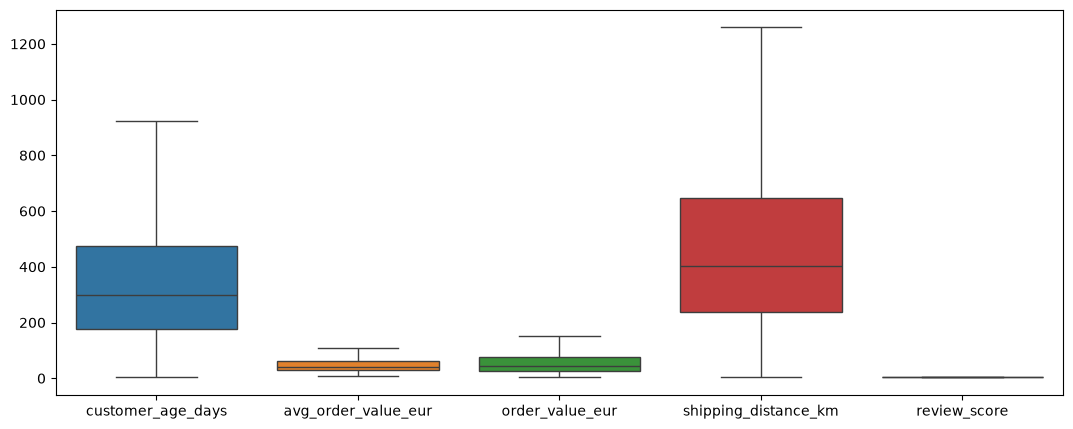

In [18]:
plt.figure(figsize=(13,5))
sns.boxplot(df[['customer_age_days','avg_order_value_eur', 'order_value_eur','shipping_distance_km','review_score']])

**Step 5: Feature Engineering**

In [19]:
df['customer_clv_proxy'] = df['previous_orders'] * df['avg_order_value_eur']

df['value_deviation_ratio'] = df['order_value_eur'] / (df['avg_order_value_eur'] + 1e-5)

country_fraud_risk = df.groupby('country')['is_fraud'].transform('mean')
df['country_fraud_risk'] = country_fraud_risk

In [20]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['day'] = df['order_date'].dt.day

**Step 6: Data Visualization**

Univariate:

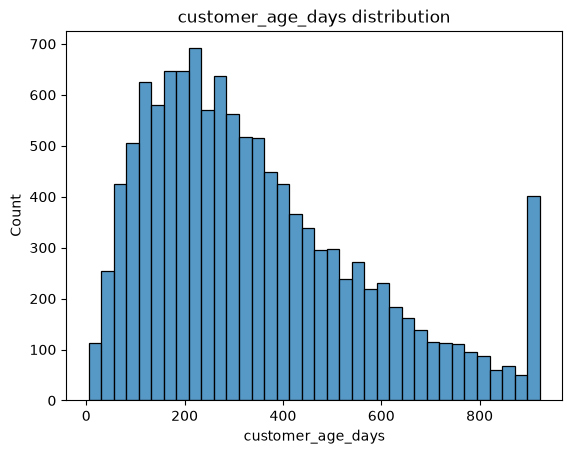

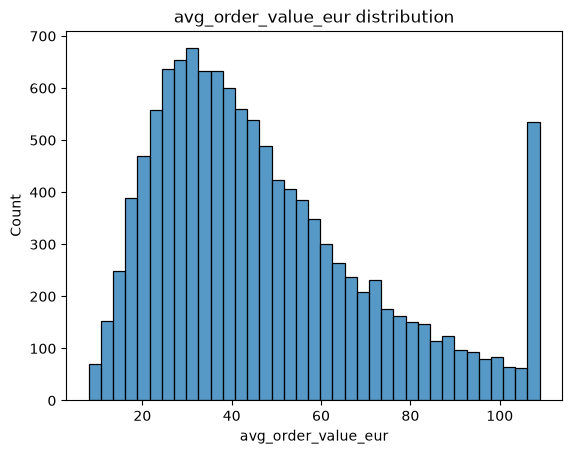

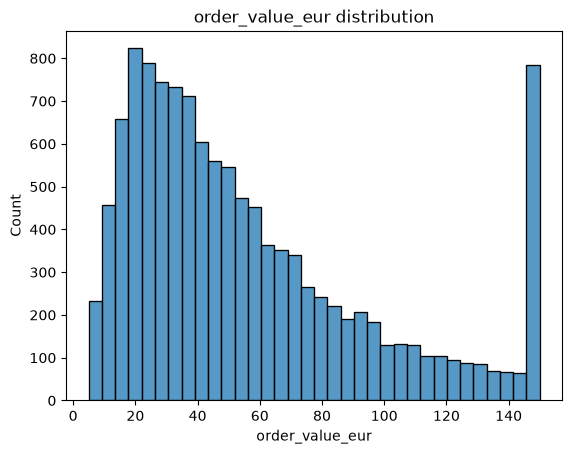

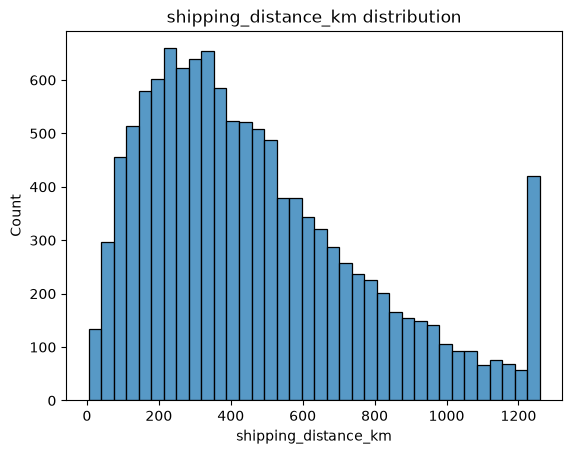

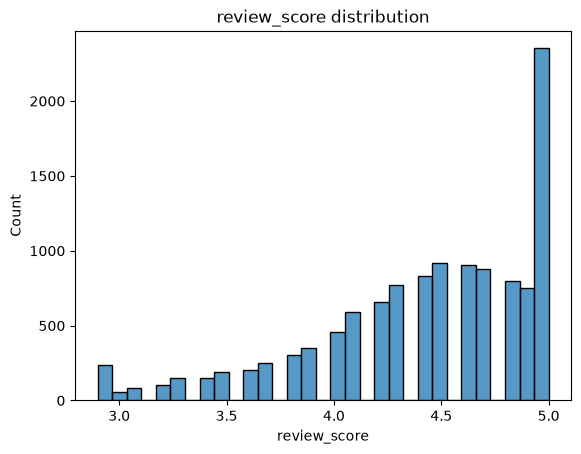

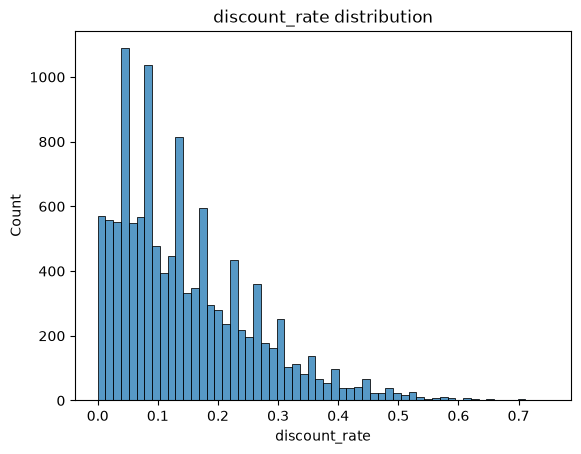

In [21]:
nums = ['customer_age_days','avg_order_value_eur', 'order_value_eur','shipping_distance_km','review_score','discount_rate']
for n in nums:
    sns.histplot(data=df,x=n)
    plt.title(f"{n} distribution")
    plt.show()

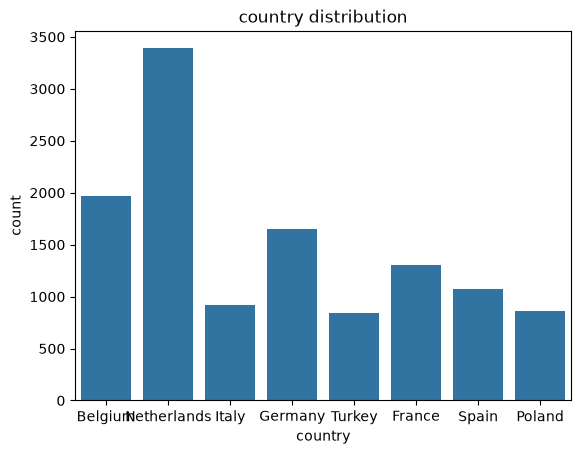

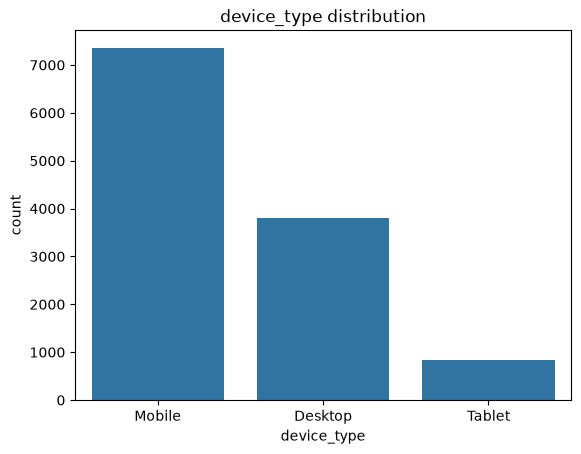

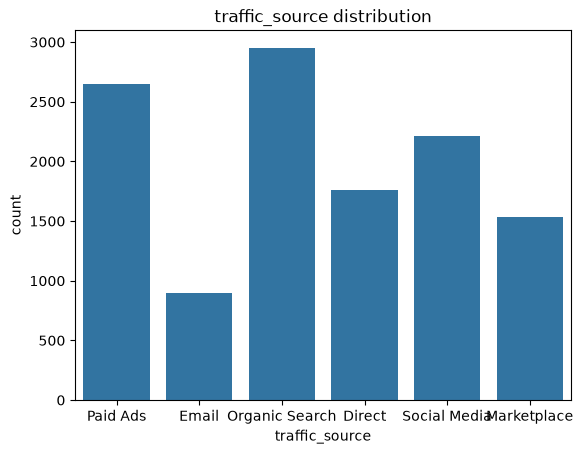

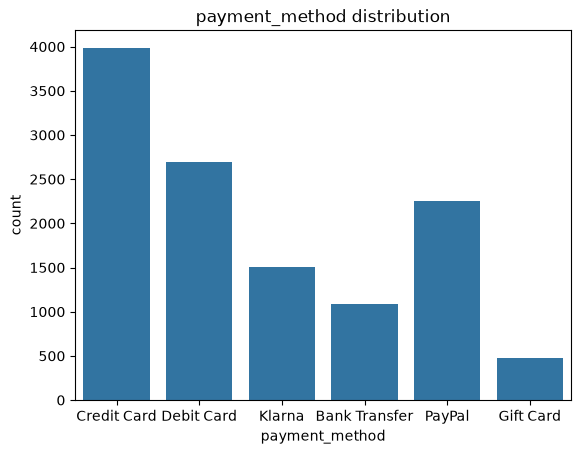

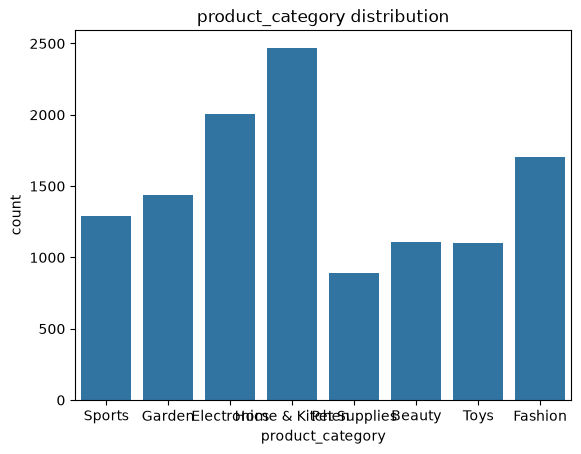

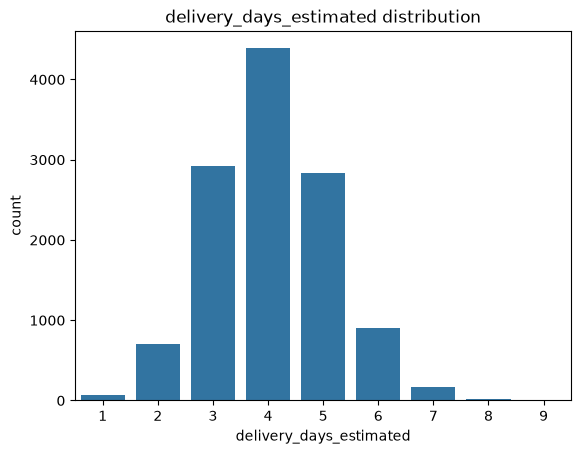

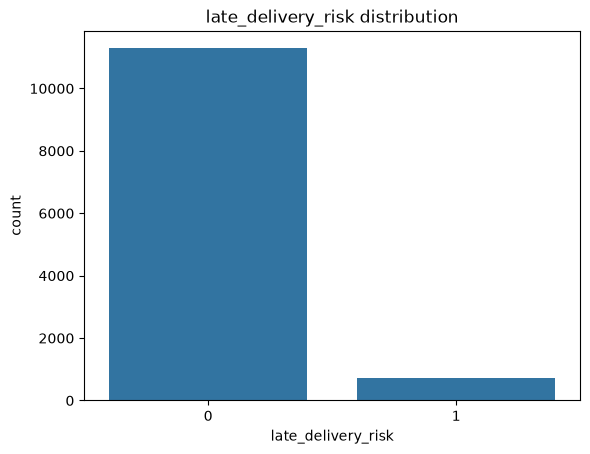

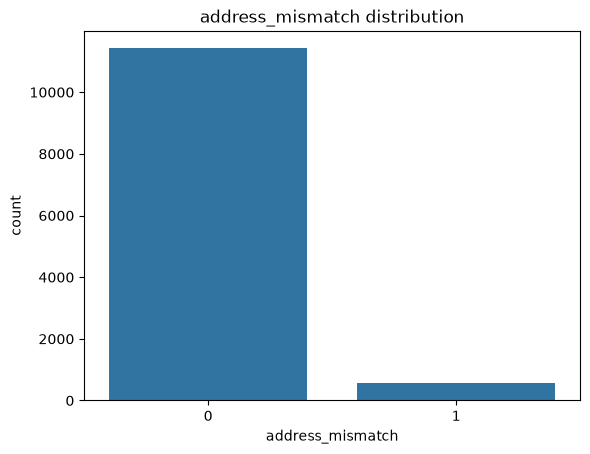

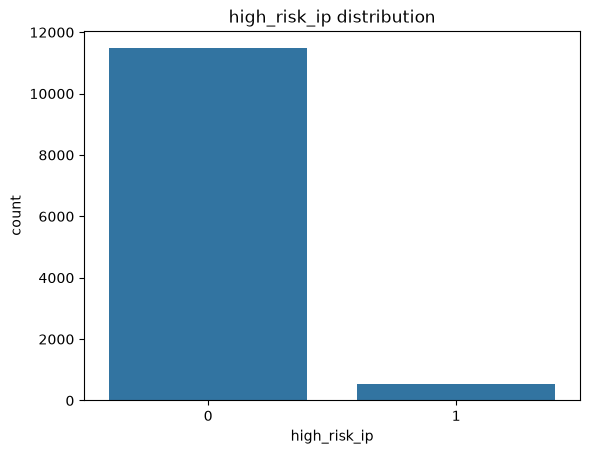

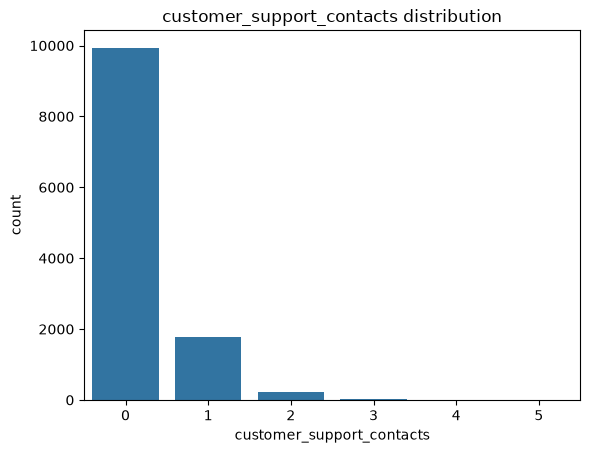

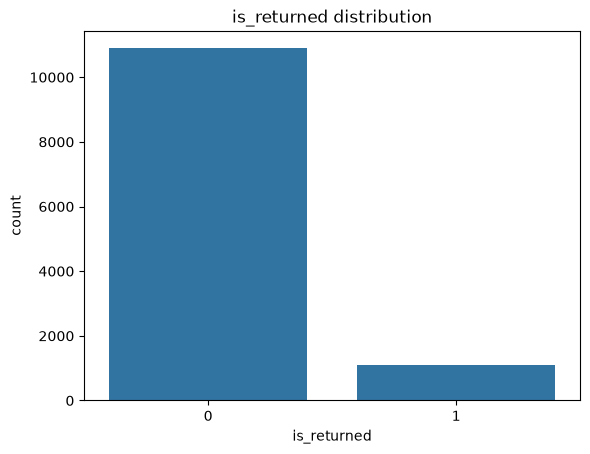

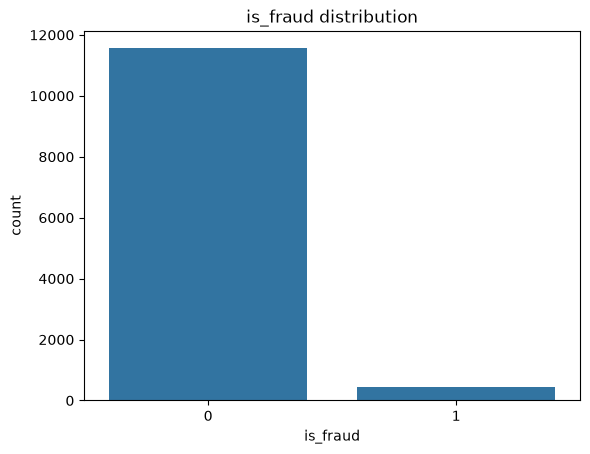

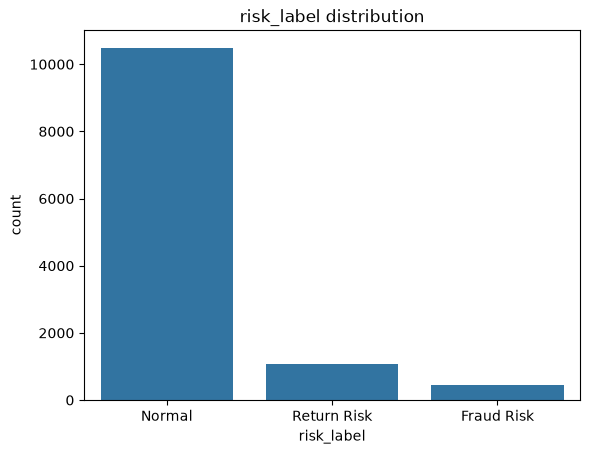

In [23]:
cats = ['country', 'device_type', 'traffic_source','payment_method', 'product_category','delivery_days_estimated','late_delivery_risk', 'address_mismatch', 'high_risk_ip','customer_support_contacts','is_returned', 'is_fraud','risk_label']
for n in cats:
    sns.countplot(data=df,x=n)
    plt.title(f"{n} distribution")
    plt.show()

Bivariate & Multivariate:

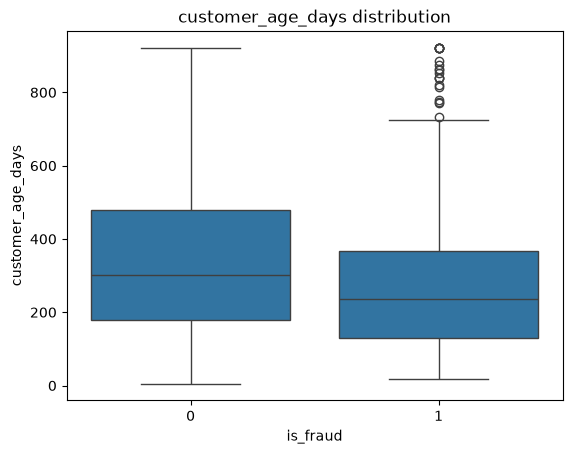

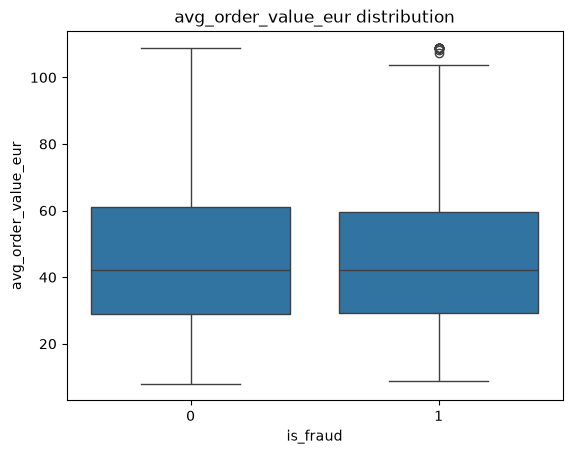

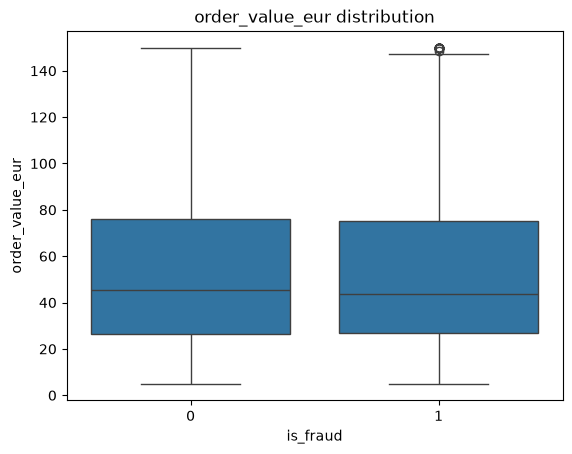

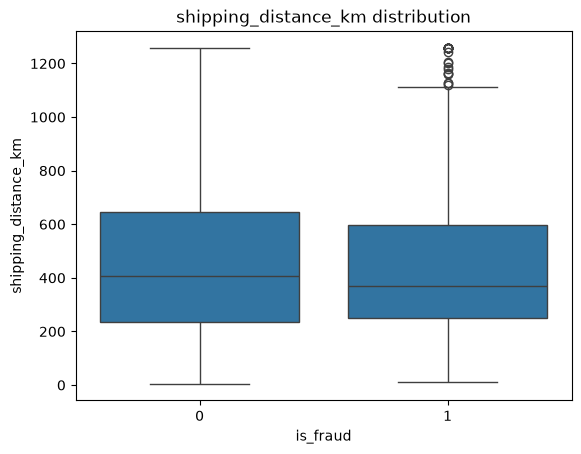

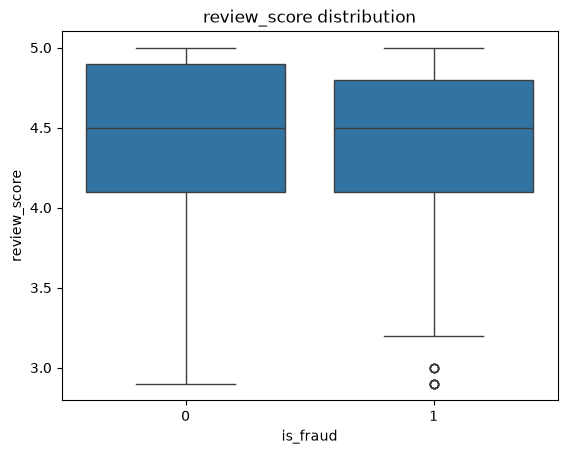

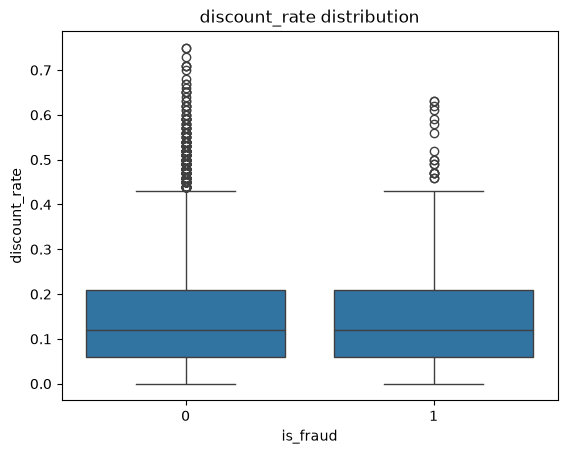

In [24]:
nums = ['customer_age_days','avg_order_value_eur', 'order_value_eur','shipping_distance_km','review_score','discount_rate']
for n in nums:
    sns.boxplot(data=df,x='is_fraud',y=n)
    plt.title(f"{n} distribution")
    plt.show()

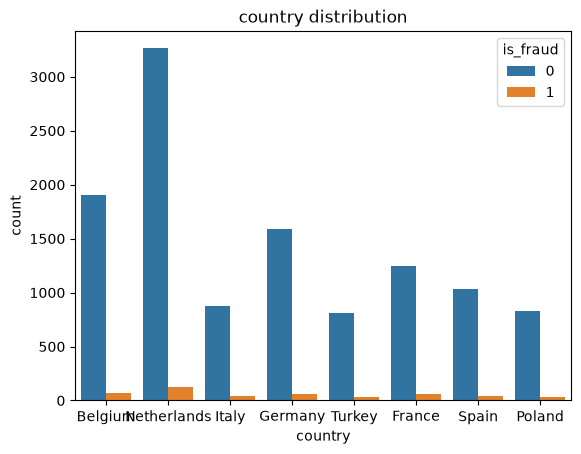

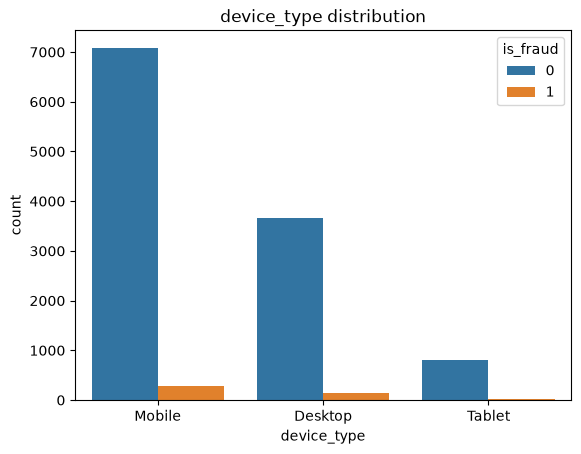

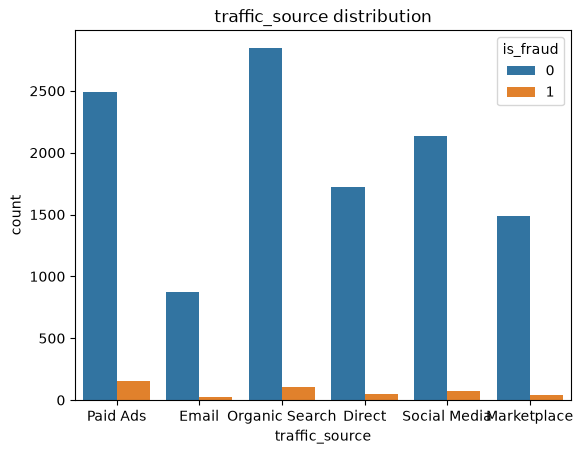

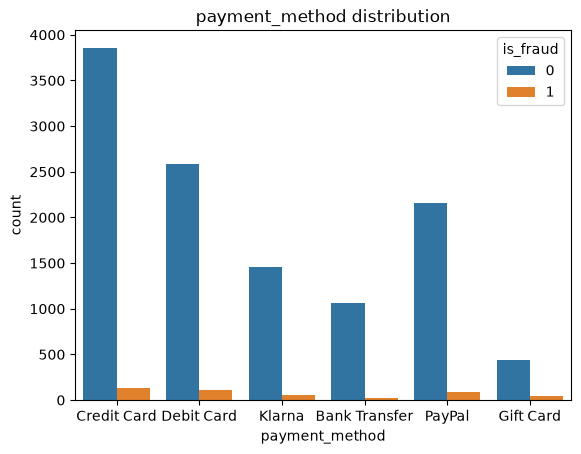

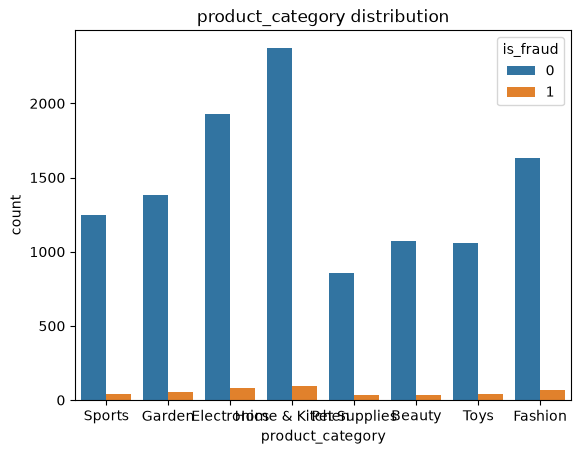

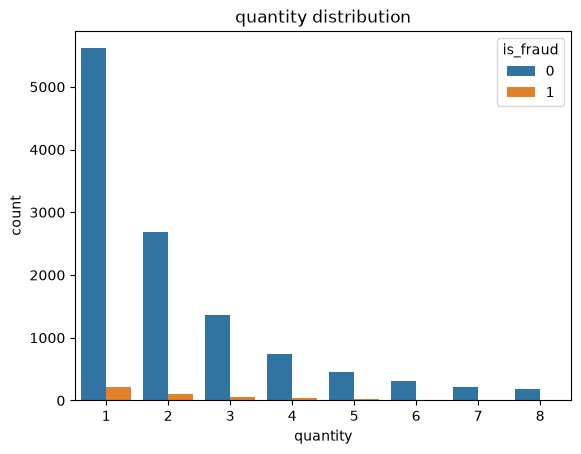

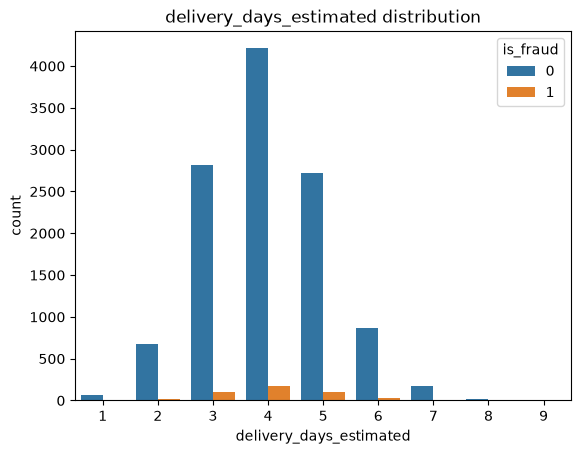

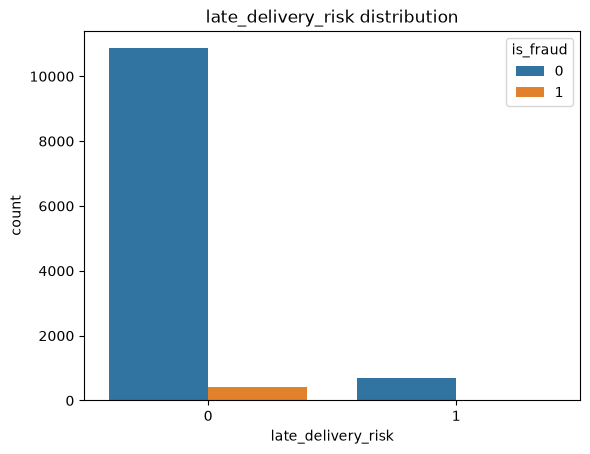

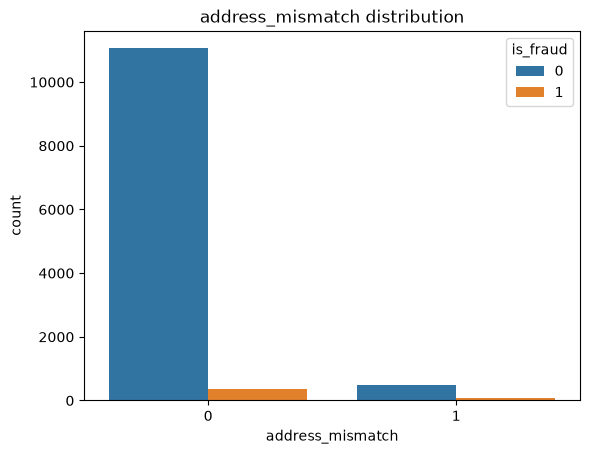

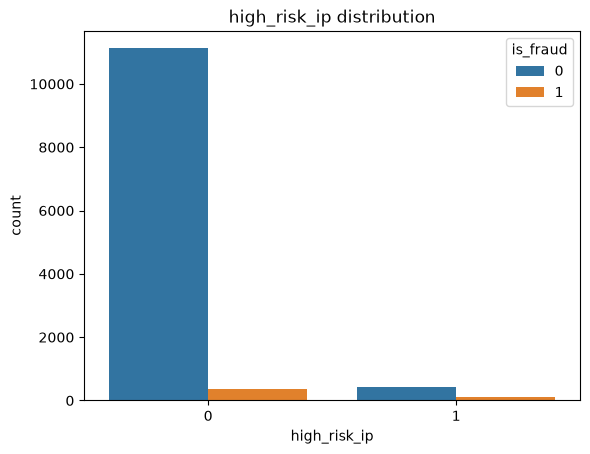

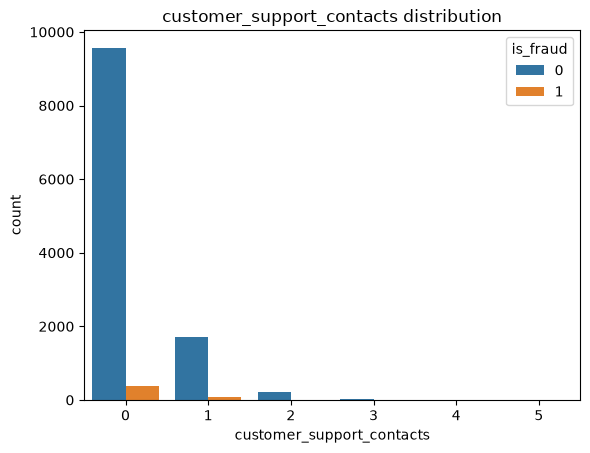

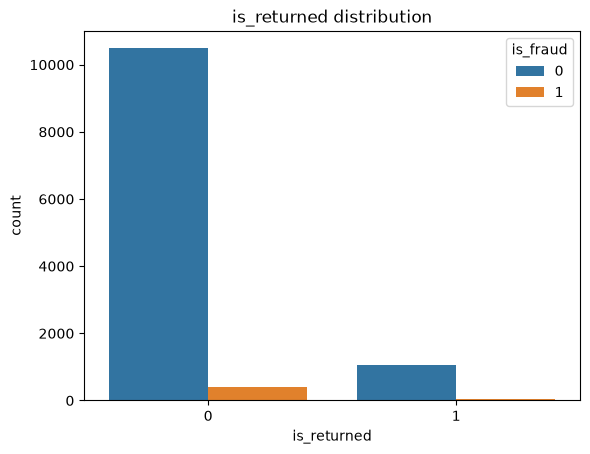

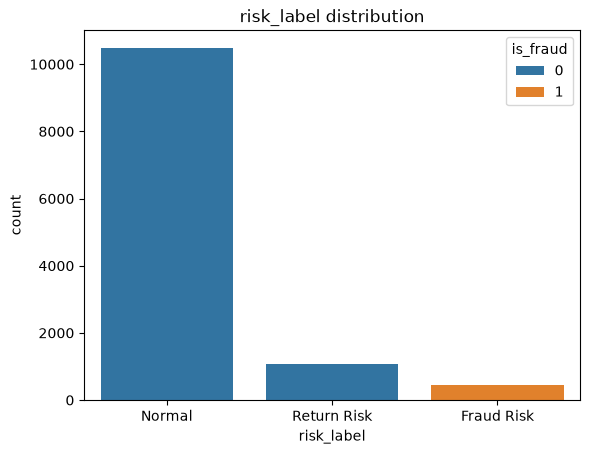

In [26]:
cats = ['country', 'device_type', 'traffic_source','payment_method', 'product_category','quantity','delivery_days_estimated','late_delivery_risk', 'address_mismatch', 'high_risk_ip','customer_support_contacts','is_returned', 'risk_label']
for n in cats:
    sns.countplot(data=df,x=n, hue='is_fraud')
    plt.title(f"{n} distribution")
    plt.show()

Correlation analysis:

<Axes: >

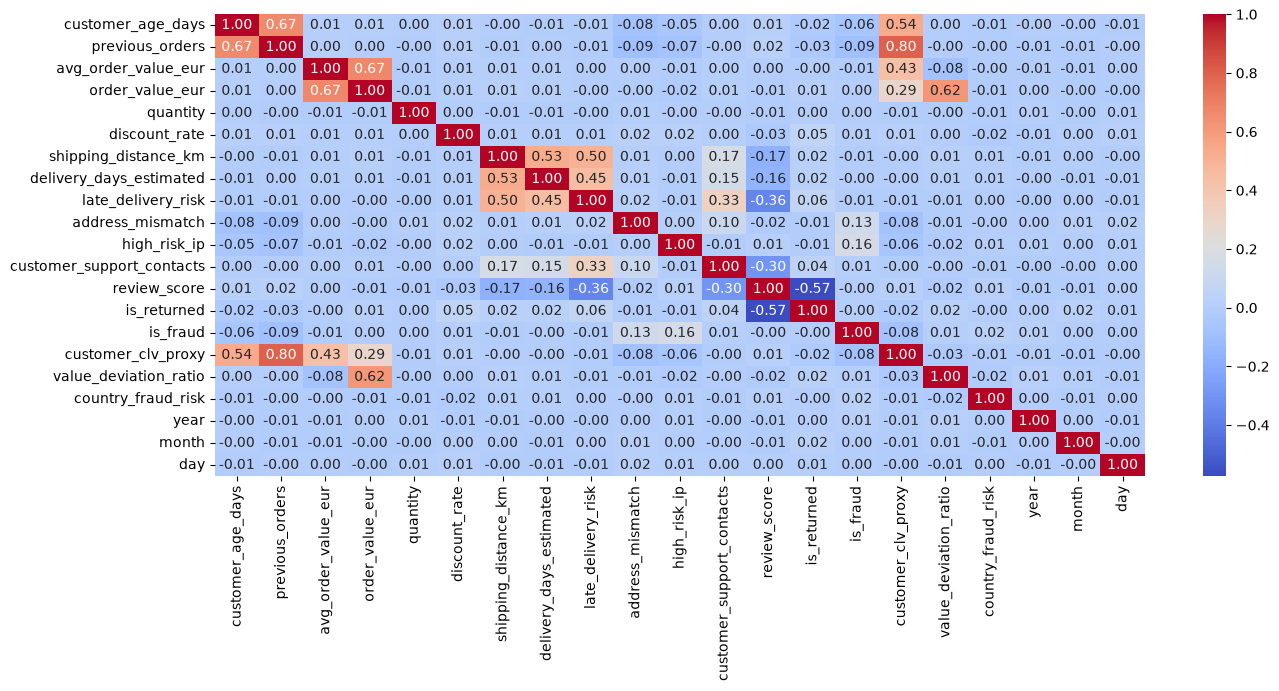

In [28]:
plt.figure(figsize=(15,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")

**Step 7: Define Features (X) and Target (y)**

In [30]:
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']

num_cols = df.select_dtypes(include=[int,float]).drop(columns=['is_fraud']).columns.to_list()
cat_cols = df.select_dtypes(include=[str]).columns.to_list()

**Step 8: Train-Test Split**

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (9600, 27) | X_test: (2400, 27)


**Step 9: Preprocessing Pipeline**

In [32]:
num_trans = Pipeline([
    ('imp',SimpleImputer(strategy="mean")),
    ('scr',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy="most_frequent")),
    ('ohe',OneHotEncoder(sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num_pre",num_trans,num_cols),
    ("cat_pre",cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [33]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

**Step 10: Feature Selection**

In [34]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_df)
X_test_sele = selector.transform(X_test_df)
print("X_train Shape before feature selection: ",X_train_df.shape)
print("X_train Shape after feature selection: ",X_train_sele.shape)
print("\nX_test Shape before feature selection: ",X_test_df.shape)
print("X_test Shape after feature selection: ",X_test_sele.shape)

X_train Shape before feature selection:  (9600, 54)
X_train Shape after feature selection:  (9600, 54)

X_test Shape before feature selection:  (2400, 54)
X_test Shape after feature selection:  (2400, 54)


**Step 11 & 12: Train Models & Regression Metrics**

In [36]:
models = {
    "Logistic Regression":LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=5, min_samples_leaf=2,random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=200,max_depth=15, min_samples_split=2, min_samples_leaf=1, n_jobs=-1, random_state=42),
    "XgBoost":XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42),
    "SVM": SVC(C=0.01, kernel='rbf', gamma='scale', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=8, n_jobs=-1),
    "Naive Bayes": GaussianNB()
}

for name, model in models.items():
    model.fit(X_train_sele, y_train)
    y_pred = model.predict(X_test_sele)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred,zero_division=0)
    pre = precision_score(y_test, y_pred,zero_division=0)
    re = recall_score(y_test, y_pred,zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}%  -> F1: {f1*100:.4f} | Precision: {pre*100:.4f}  -> Recall: {re*100:.4f}")

[Logistic Regression] -> Accuracy: 100.00%  -> F1: 100.0000 | Precision: 100.0000  -> Recall: 100.0000
[Decision Tree] -> Accuracy: 100.00%  -> F1: 100.0000 | Precision: 100.0000  -> Recall: 100.0000
[Random Forest] -> Accuracy: 100.00%  -> F1: 100.0000 | Precision: 100.0000  -> Recall: 100.0000
[XgBoost] -> Accuracy: 100.00%  -> F1: 100.0000 | Precision: 100.0000  -> Recall: 100.0000
[SVM] -> Accuracy: 96.50%  -> F1: 0.0000 | Precision: 0.0000  -> Recall: 0.0000
[KNN] -> Accuracy: 96.58%  -> F1: 4.6512 | Precision: 100.0000  -> Recall: 2.3810
[Naive Bayes] -> Accuracy: 100.00%  -> F1: 100.0000 | Precision: 100.0000  -> Recall: 100.0000


**Step 13: Cross Validation**

In [37]:
lr_validator = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
cv_score = cross_val_score(lr_validator, X_train_sele, y_train, cv=3, scoring='accuracy')
print(f"3-Fold cross validation accuracy matrix: {cv_score}")
print(f"Cross validation Score: {cv_score.mean()*100:.2f}%")

3-Fold cross validation accuracy matrix: [1. 1. 1.]
Cross validation Score: 100.00%


**Step 14: Hyperparameter Tuning**

In [38]:
param_grid = {
    'solver': ['saga'],                  # 👈 Crucial fix: Move solver here
    'C': [0.01, 0.1, 1, 10, 100],
    'l1_ratio': [0.0, 0.5, 1.0],         # 0.0=L2, 0.5=ElasticNet, 1.0=L1
    'max_iter': [4000]                   # SAGA requires more iterations to converge
}

grid_search = GridSearchCV(
    estimator=lr_validator,
    param_grid=param_grid,
    scoring='accuracy',
    cv=3
)

grid_search.fit(X_train_sele, y_train)
best_tuned_regressor = grid_search.best_estimator_

print("Best parameters: ",grid_search.best_params_)
print("Best score: ",grid_search.best_score_)

Best parameters:  {'C': 0.01, 'l1_ratio': 1.0, 'max_iter': 4000, 'solver': 'saga'}
Best score:  1.0


In [39]:
check_regressor = LogisticRegression(C=0.01,l1_ratio=1.0,max_iter=4000,solver='saga')
check_regressor.fit(X_train_processed, y_train)

y_pred = check_regressor.predict(X_test_processed)
print(f"Logistic Verification Test accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")

Logistic Verification Test accuracy: 100.00%


**Step 15: Feature Importance**

In [40]:
# Changed .feature_importances_ to .coef_[0] because Logistic Regression uses coefficients
important = pd.DataFrame({
    "Feature": X_train_df.columns[selector.get_support()],
    "Importance": best_tuned_regressor.coef_[0]
}).sort_values(by="Importance", ascending=False) 

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(important.head(10))



--- TOP FEATURE IMPORTANCE SCORES ---
                             Feature  Importance
51    cat_pre__risk_label_Fraud Risk    5.481138
0         num_pre__customer_age_days    0.000000
2       num_pre__avg_order_value_eur    0.000000
3           num_pre__order_value_eur    0.000000
4                  num_pre__quantity    0.000000
1           num_pre__previous_orders    0.000000
6      num_pre__shipping_distance_km    0.000000
7   num_pre__delivery_days_estimated    0.000000
8        num_pre__late_delivery_risk    0.000000
9          num_pre__address_mismatch    0.000000


**Step 16: Final Pipeline Production**

In [41]:
final_production_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("selector",selector),
    ("regressor",best_tuned_regressor)
])
final_production_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['order_date','country','device_type',...,'year','month','day']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_pre', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

**Step 17: Save Model & Load Model**

In [42]:
model_payload = pd.DataFrame({
    "model_pipeline":final_production_pipeline,
    "Features":X_train_df.columns[selector.get_support()]
})

joblib.dump(model_payload,"logistic_pipeline.pkl")
print("Model saved successfully!")

Model saved successfully!


In [43]:
joblib.load("logistic_pipeline.pkl")
print("Model loaded successfully!")

Model loaded successfully!
